# STUDENT LAB WORKSHEET: Klasifikace v praxi – Od logistické regrese po rozhodovací stromy

**Odhadovaná délka:** 80 minut
**Předchozí znalosti:** Základy jazyka Python, knihovny Pandas a NumPy.

### Co se naučíte (Výstupy učení)

Po úspěšném dokončení tohoto cvičení:

1. **Použijete** knihovnu `scikit-learn` k rozdělení dat, jejich standardizaci a natrénování modelů.


2. **Zdůvodníte** proces oddělené transformace testovací sady pro zabránění úniku dat (tzv. data leakage).


3. **Interpretujete** výstupy evaluační funkce `classification_report` v kontextu obchodní úlohy.


4. **Porovnáte** geometrii rozhodovacích hranic lineárního a nelineárního modelu na základě vizualizací.


5. **Vyhodnotíte** robustnost modelu samostatnou implementací křížové validace (K-fold).



---

## 1. Kontext a motivace

Představte si, že jste datový analytik. Máte k dispozici historická data o uživatelích – znáte jejich věk (`Age`), odhadovaný plat (`EstimatedSalary`) a víte, zda si koupili nabízený produkt (`Purchased` = 0 nebo 1). Vaším úkolem je postavit klasifikační model (model strojového učení zařazující data do tříd), který na základě věku a platu automaticky předpoví, zda nový uživatel nákup uskuteční. Cílem je srovnat dva odlišné přístupy: Logistickou regresi a Rozhodovací stromy.

---

## 2. Příprava dat a klíčové pojmy

V každém projektu strojového učení je prvním krokem načtení dat a jejich rozdělení na matici vlastností (příznaků) a vektor cílových hodnot (to, co chceme predikovat).

**Instrukce:** Spusťte následující kód, který stáhne data a připraví proměnné `X` a `y`. Všimněte si použití metody `.iloc` pro extrakci sloupců. Dále kód importuje základní knihovny pro zbytek cvičení.

In [31]:
# Import základních knihoven
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Stažení datového souboru z Google Drive
# Soubor Social_Network_Ads.csv už máme lokálně ve složce, wget proto není potřeba.
# !wget -q -O 'Social_Network_Ads.csv' 'url na gdrive'

# Načtení dat pomocí Pandas
dataset = pd.read_csv('Social_Network_Ads.csv')

# Vytvoření matice příznaků X (vše kromě posledního sloupce)
X = dataset.iloc[:, :-1].values

# Vytvoření vektoru cílových hodnot y (pouze poslední sloupec)
y = dataset.iloc[:, -1].values

# Zobrazení prvních 5 řádků
dataset.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


### Explorace dat

Dříve než začneme trénovat model, je dobré podívat se na rozložení naší cílové proměnné.

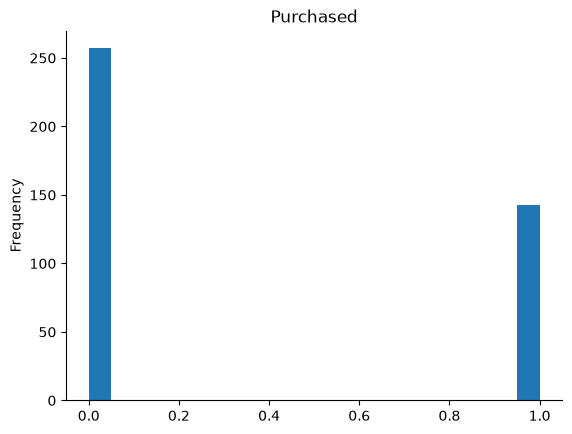

Purchased
0    257
1    143
Name: count, dtype: int64
Purchased
0    0.642
1    0.358
Name: proportion, dtype: float64


In [32]:
# Vykreslení histogramu cílové proměnné
dataset['Purchased'].plot(kind='hist', bins=20, title='Purchased')
plt.gca().spines[['top', 'right',]].set_visible(False)
plt.show()

# Kvantitativní kontrola vyváženosti
print(dataset['Purchased'].value_counts())
print(dataset['Purchased'].value_counts(normalize=True).round(3))

> **Pozorování a otázka:**
> Podívejte se na vykreslený graf. Jsou data tzv. vyvážená (je počet uživatelů, kteří nakoupili a nenakoupili, zhruba stejný)? Jaký to může mít vliv na hodnocení modelu?

> **Odpověď:**
> Data vyvážená nejsou. Nenakoupilo 257 lidí (asi 64 %) a nakoupilo jen 143 (asi 36 %), takže nekupujících je zhruba dvakrát víc.
> Problém je v tom, že kdyby model prostě vždycky tipnul „nenakoupí“, měl by i tak přesnost kolem 64 %, a přitom by nenašel ani jednoho kupce. Accuracy samotná nám proto moc neřekne a je potřeba koukat i na precision a recall u třídy 1.

---

## 3. Rozdělení dat a Feature Scaling

Nyní data rozdělíme pomocí **Train/Test Split**. Trénovací část (obvykle 80 %) slouží k učení modelu, testovací (20 %) k objektivnímu ověření.
Následuje **Feature Scaling (Škálování příznaků)**. Protože hodnoty platu jsou v desetitisících a hodnoty věku v desítkách, musíme je standardizovat (převést na podobné měřítko, zde průměr 0 a rozptyl 1), aby plat matematicky „nepřehlušil“ věk.

**Instrukce:** Pečlivě si prohlédněte způsob volání transformací ve scikit-learn.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Rozdělení dat na trénovací a testovací sadu (Aktivní úkol: test_size = 0.3 -> 70:30)
# random_state=0 zajistí reprodukovatelnost výsledků
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0)
print(f"Trénovací vzorky: {X_train.shape[0]}, testovací vzorky: {X_test.shape[0]}")

# Inicializace škálovače
sc = StandardScaler()

# Škálování trénovacích dat - model se UČÍ parametry a rovnou TRANSFORMUJE
X_train = sc.fit_transform(X_train)

# Škálování testovacích dat - ZÁSADNÍ ROZDÍL
# mean and std are known at this point (průměr a odchylka jsou již známé)
X_test = sc.transform(X_test)

print("Ukázka testovacích dat po škálování:")
print(X_test[:5])
print("\nKontrola škálování (train): průměr =", X_train.mean(axis=0).round(3), ", směr. odchylka =", X_train.std(axis=0).round(3))

Trénovací vzorky: 280, testovací vzorky: 120
Ukázka testovacích dat po škálování:
[[-0.77101313  0.49720103]
 [ 0.0133054  -0.57280368]
 [-0.28081405  0.15017248]
 [-0.77101313  0.26584866]
 [-0.28081405 -0.57280368]]

Kontrola škálování (train): průměr = [0. 0.] , směr. odchylka = [1. 1.]


> **Typická chyba a kritické zhodnocení (Data Leakage):**
> *Didaktické upozornění:* Proč na testovací data voláme výhradně metodu `.transform()` a nikoliv `.fit_transform()`? Pokud bychom scaler "naučili" (fit) i na testovacích datech, statistické informace z testovací sady by unikly do trénovací fáze (tzv. Data Leakage). Model by při testování v podstatě "podváděl".
>
>

**Aktivní úkol:** V kódu výše zkuste změnit parametr `test_size` na `0.3` (30 % dat pro testování) a buňku znovu spusťte. Promítněte si, jak tato změna ovlivní počet vzorků pro trénink.

> **Odpověď:**
> Testovací data mají představovat nové zákazníky, které model ještě neviděl. Scaler si proto průměr a odchylku spočítá jen z trénovacích dat (`fit_transform`) a testovací data se podle těchto hodnot jen přepočítají (`transform`). Kdybychom udělali `fit` i na testu, model by vlastně dopředu „nakoukl“ do testovacích dat a výsledek by vyšel lepší, než ve skutečnosti je.
>
> **Aktivní úkol:** Dataset má 400 řádků. Při `test_size = 0.2` je to 320 řádků na trénink a 80 na test, při `0.3` je to 280 na trénink a 120 na test. Model se tedy učí z o něco menšího množství dat, ale zase ho testujeme na víc vzorcích, takže je výsledek spolehlivější. (Přidal jsem ještě `random_state=0`, aby mi vycházela pořád stejná čísla.)
>
> **Predikce pro uživatele (30 let, plat 87 000):** model vrátil 0, tedy nenakoupí. Pravděpodobnost nákupu mu vyšla jen asi 11 %. Dává to smysl, protože z dat je vidět, že nakupují spíš starší lidé nebo lidi s vyšším platem.

---

## 4. Trénink modelu (Logistická regrese) a Predikce

Logistická regrese je základní lineární klasifikátor. Zkusíme model natrénovat a předpovědět chování konkrétního uživatele (věk 30, plat 87 000).

In [34]:
from sklearn.linear_model import LogisticRegression

# Inicializace a trénink modelu
LRclassifier = LogisticRegression()
LRclassifier.fit(X_train, y_train)

# Predikce pro nového uživatele (Věk: 30, Plat: 87000)
age = 30
salary = 87000

# Uživatele musíme před predikcí zaškálovat stejným způsobem!
ex_scaled = sc.transform([[age, salary]])

# Samotná predikce (0 = nenakoupí, 1 = nakoupí)
prediction = LRclassifier.predict(ex_scaled)
print(f"Predikce pro uživatele (věk {age}, plat {salary}): {prediction}")
print(f"Pravděpodobnost nákupu: {LRclassifier.predict_proba(ex_scaled)[0, 1]:.3f}")

Predikce pro uživatele (věk 30, plat 87000): [0]
Pravděpodobnost nákupu: 0.112


### Classification Report (Evaluace)

Znalost pouhého procenta správných odpovědí (Accuracy) u nevyvážených dat nestačí. Proto používáme **Classification Report**, který zavádí metriky jako *precision* (kolik % z těch, které model označil za kupující, opravdu nakoupilo) a *recall* (jaké % všech skutečných kupujících model úspěšně odhalil).

In [35]:
from sklearn.metrics import classification_report

# Predikce na celé testovací sadě
y_pred_lr = LRclassifier.predict(X_test)

# Výpis metrik
print("--- Classification Report: Logistic Regression ---")
print(classification_report(y_test, y_pred_lr))

from sklearn.metrics import confusion_matrix
print("Matice záměn (řádky = skutečnost 0/1, sloupce = predikce 0/1):")
print(confusion_matrix(y_test, y_pred_lr))

--- Classification Report: Logistic Regression ---
              precision    recall  f1-score   support

           0       0.87      0.94      0.90        79
           1       0.86      0.73      0.79        41

    accuracy                           0.87       120
   macro avg       0.86      0.83      0.85       120
weighted avg       0.87      0.87      0.86       120

Matice záměn (řádky = skutečnost 0/1, sloupce = predikce 0/1):
[[74  5]
 [11 30]]


> **Otázka k interpretaci:**
> Jaké hodnoty `precision` a `recall` váš model dosahuje pro třídu `1` (nakupující)? Zkuste na základě těchto čísel říct, v čem model chybuje častěji (zda označuje ne-kupující za kupující, nebo naopak míjí skutečné kupce).

> **Odpověď:**
> Pro třídu 1 (kupující) vyšla precision 0.86 a recall 0.73, celková accuracy je 0.87.
> Z matice záměn je vidět, že model 5 lidí označil za kupující, i když nenakoupili, ale 11 skutečných kupců úplně minul. Častěji tedy chybuje tím, že **přehlédne skutečné kupce**. Když už někoho označí za kupujícího, většinou má pravdu, jenže zhruba čtvrtinu zákazníků nenajde.

---

## 5. Vizualizace hranic a Rozhodovací stromy

Nyní si ukážeme, jak si model "rozřízl" prostor dat na zónu nákupu a zónu odmítnutí. Pro srovnání rovnou natrénujeme nelineární model – Rozhodovací strom (Decision Tree).

> **Technické upozornění:** Kód níže používá knihovnu Matplotlib k vykreslení složité maticové mřížky (`np.meshgrid`). Při spuštění pravděpodobně uvidíte varování `UserWarning: *c* argument looks like a single numeric RGB...`. Nelekejte se, nejedná se o chybu vaší logiky, jde pouze o varování na starší styl zápisu barev v Matplotlibu. Kód nespravujte.
>
>

--- Classification Report: Decision Tree ---
              precision    recall  f1-score   support

           0       0.95      0.89      0.92        79
           1       0.80      0.90      0.85        41

    accuracy                           0.89       120
   macro avg       0.88      0.89      0.88       120
weighted avg       0.90      0.89      0.89       120

Matice záměn:
[[70  9]
 [ 4 37]]


/var/folders/kp/bhjy3s4932s5r2h5q80fs3gr0000gn/T/ipykernel_68440/1910562665.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


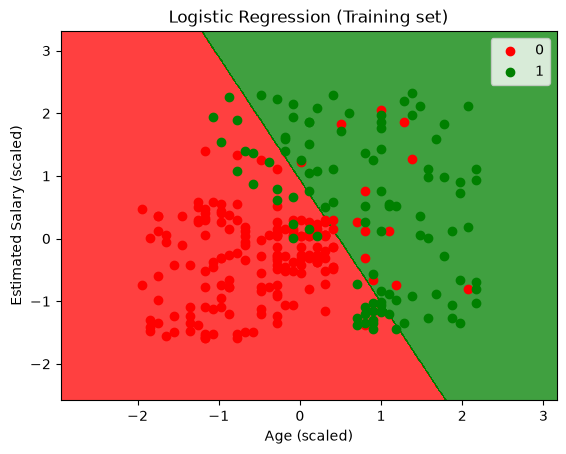

/var/folders/kp/bhjy3s4932s5r2h5q80fs3gr0000gn/T/ipykernel_68440/1910562665.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


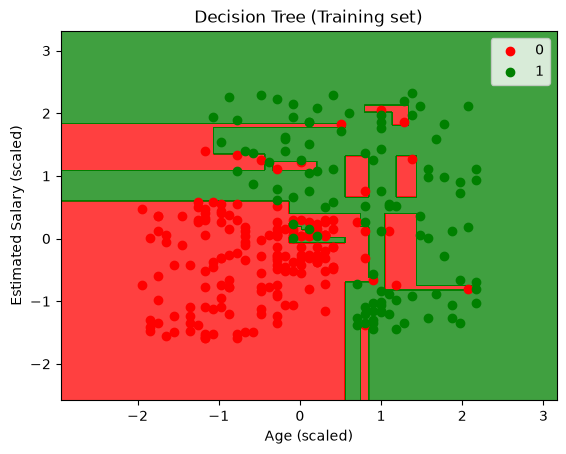

In [36]:
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import ListedColormap

# Trénink rozhodovacího stromu (entropie jako kritérium dělení)
DTclassifier = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
# Didaktická poznámka: Stromy reálně standardizaci nevyžadují, ale pro zachování
# srovnatelnosti dimenzí zde použijeme stejná škálovaná data jako výše.
DTclassifier.fit(X_train, y_train)

# Predikce a report pro strom
y_pred_dt = DTclassifier.predict(X_test)
print("--- Classification Report: Decision Tree ---")
print(classification_report(y_test, y_pred_dt))
print("Matice záměn:")
print(confusion_matrix(y_test, y_pred_dt))

# --- VIZUALIZACE (pouze trénovací data) ---
def plot_decision_regions(X_set, y_set, classifier, title):
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                         np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
    plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
                 alpha = 0.75, cmap = ListedColormap(('red', 'green')))
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                    c = ListedColormap(('red', 'green'))(i), label = j) # Zde Matplotlib generuje UserWarning
    plt.title(title)
    plt.xlabel('Age (scaled)')
    plt.ylabel('Estimated Salary (scaled)')
    plt.legend()
    plt.show()

# Vykreslení obou modelů
plot_decision_regions(X_train, y_train, LRclassifier, 'Logistic Regression (Training set)')
plot_decision_regions(X_train, y_train, DTclassifier, 'Decision Tree (Training set)')

> **Srovnání (Zhodnocení):**
> Jaký geometrický tvar má dělící hranice u Logistické regrese a jaký u Rozhodovacího stromu? Dokážete zdůvodnit, proč strom tvoří "pravoúhlé" rohy?

> **Odpověď:**
> U logistické regrese je hranice **rovná čára**. Je to lineární model, takže prostor umí rozdělit jen jedním rovným řezem.
> U rozhodovacího stromu je hranice **„schodovitá“, složená z obdélníků**. Strom se v každém kroku ptá jen na jednu proměnnou, třeba „je věk menší než X?“. Každá taková otázka udělá čáru rovnoběžnou s jednou z os, a proto tam vznikají jen vodorovné a svislé čáry s pravými úhly.
> Strom vyšel na testu o něco líp (accuracy 0.89 a hlavně recall u kupců 0.90 oproti 0.73). Na grafu je ale vidět, že si dělá i malé ostrůvky kolem jednotlivých bodů. To je spíš znak toho, že se data naučil moc nazpaměť (overfitting).

---

## 6. Křížová validace (K-Fold CV)

Pokud náhodně rozdělíme data pomocí `train_test_split`, může mít model jen "štěstí" (nebo smůlu) na konkrétní složení testovací sady. **Křížová validace** (K-Fold) rozdělí kompletní dataset na `K` (zde 5) částí. Model se trénuje K-krát, přičemž pokaždé je jako testovací použita jiná část.

In [37]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

# Nastavení validace na 5 splitů
kf = KFold(shuffle=True, n_splits=5, random_state=0)

# Spuštění křížové validace nad logistickou regresí
# Upozornění: Funkce cross_val_score si vnitřně trénuje a testuje model sama.
scores = cross_val_score(LRclassifier, X, y, cv=kf)

print("Výsledky pro 5 iterací (Logistická regrese):")
print(scores)
print(f"Průměrná přesnost (Accuracy): {np.mean(scores):.4f}")
print(f"Směrodatná odchylka: {np.std(scores):.4f}")

Výsledky pro 5 iterací (Logistická regrese):
[0.9125 0.8125 0.75   0.8    0.9375]
Průměrná přesnost (Accuracy): 0.8425
Směrodatná odchylka: 0.0710


In [38]:
# Rozšíření: korektní křížová validace se škálováním uvnitř každého foldu (Pipeline)
# a srovnání s rozhodovacím stromem. Pipeline zajistí, že se scaler fituje jen na
# trénovací části daného foldu -> žádný data leakage.
from sklearn.pipeline import make_pipeline

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression())
scores_lr_pipe = cross_val_score(lr_pipe, X, y, cv=kf)
scores_dt = cross_val_score(DecisionTreeClassifier(criterion='entropy', random_state=0), X, y, cv=kf)

print("Logistická regrese + StandardScaler (Pipeline):", scores_lr_pipe.round(4))
print(f"  průměr = {scores_lr_pipe.mean():.4f}, std = {scores_lr_pipe.std():.4f}")
print("Rozhodovací strom:", scores_dt.round(4))
print(f"  průměr = {scores_dt.mean():.4f}, std = {scores_dt.std():.4f}")

Logistická regrese + StandardScaler (Pipeline): [0.925 0.8   0.75  0.8   0.95 ]
  průměr = 0.8450, std = 0.0781
Rozhodovací strom: [0.9    0.8375 0.775  0.85   0.95  ]
  průměr = 0.8625, std = 0.0592


> **Odpověď:**
> Výsledky v jednotlivých foldech se dost liší, zhruba od 0.75 do 0.94, a průměr vyšel asi 0.84. Je tedy vidět, že jeden `train_test_split` může dopadnout lépe nebo hůř podle toho, jaká data se zrovna dostanou do testu. Průměr z 5 foldů je proto spolehlivější číslo.
> V další buňce jsem to zkusil ještě se škálováním přes `Pipeline` (scaler se tak učí v každém foldu znovu jen z trénovací části) a vyšlo to skoro stejně, asi 0.845. Strom měl v křížové validaci 0.86.

---

## 7. Samostatný úkol: Klasifikace číslic (Digits)

Vaším úkolem je aplikovat postup, který jste se právě naučili, na nová data. Místo chování zákazníků budeme rozpoznávat obrázky ručně psaných číslic (0 až 9).

Dataset `digits` má tvar `(1797, 64)`. Je to 1797 obrázků. Každý obrázek má 8x8 pixelů, které jsou narovnány do vektoru o velikosti 64 prvků.

Tvar matice příznaků: (1797, 64)


<Figure size 640x480 with 0 Axes>

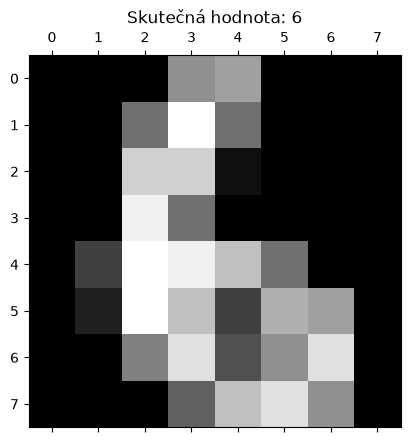

In [39]:
from sklearn.datasets import load_digits

# Načtení dat
digits = load_digits()
print(f"Tvar matice příznaků: {digits.data.shape}")

# Vykreslení ukázky (čísla 65)
plt.gray()
plt.matshow(digits.images[65])
plt.title(f"Skutečná hodnota: {digits.target[65]}")
plt.show()

**ZADÁNÍ ÚKOLU:**
Doplňte kód do následující buňky a aplikujte modely na proměnné `X_digits` a `y_digits`. Pro stromy škálování pomocí `StandardScaler` není nutné, u logistické regrese ano.

In [40]:
# Načtení X a y
X_digits = digits.data
y_digits = digits.target

from sklearn.pipeline import make_pipeline

# TODO 1: Rozdělte X_digits a y_digits na trénovací a testovací sadu (např. 80:20).
# stratify zajistí stejné zastoupení všech 10 číslic v obou sadách
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_digits, y_digits, test_size=0.2, random_state=0, stratify=y_digits)
print(f"Trénovací sada: {X_train_d.shape}, testovací sada: {X_test_d.shape}")

# TODO 2 (Pouze pro Logistickou regresi, u stromu můžete vynechat):
# Škálování dat pomocí StandardScaler. Pamatujte na fit_transform vs transform!
sc_d = StandardScaler()
X_train_d_sc = sc_d.fit_transform(X_train_d)   # fit pouze na trénovacích datech
X_test_d_sc = sc_d.transform(X_test_d)         # testovací data jen transformujeme

# TODO 3: Inicializujte model (vyberte si LogisticRegression nebo DecisionTreeClassifier)
# a natrénujte ho metodou .fit()
# Natrénujeme oba modely, abychom je mohli porovnat.
LR_d = LogisticRegression(max_iter=1000)   # víc iterací kvůli 64 příznakům a 10 třídám
LR_d.fit(X_train_d_sc, y_train_d)

DT_d = DecisionTreeClassifier(criterion='entropy', random_state=0)
DT_d.fit(X_train_d, y_train_d)              # strom škálování nepotřebuje

# TODO 4: Vygenerujte predikce na testovací sadě a vypište classification_report
y_pred_lr_d = LR_d.predict(X_test_d_sc)
y_pred_dt_d = DT_d.predict(X_test_d)
print("\n--- Classification Report: Logistic Regression (Digits) ---")
print(classification_report(y_test_d, y_pred_lr_d))
print("--- Classification Report: Decision Tree (Digits) ---")
print(classification_report(y_test_d, y_pred_dt_d))

# TODO 5: Vypište průměrné skóre z křížové validace (KFold + cross_val_score)
kf_d = KFold(n_splits=5, shuffle=True, random_state=0)
# U LR dáme škálování do Pipeline, aby se scaler fitoval v každém foldu znovu (bez data leakage)
cv_lr_d = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                          X_digits, y_digits, cv=kf_d)
cv_dt_d = cross_val_score(DecisionTreeClassifier(criterion='entropy', random_state=0),
                          X_digits, y_digits, cv=kf_d)
print("KFold CV – Logistická regrese:", cv_lr_d.round(4), f"-> průměr {cv_lr_d.mean():.4f} (± {cv_lr_d.std():.4f})")
print("KFold CV – Rozhodovací strom: ", cv_dt_d.round(4), f"-> průměr {cv_dt_d.mean():.4f} (± {cv_dt_d.std():.4f})")

Trénovací sada: (1437, 64), testovací sada: (360, 64)

--- Classification Report: Logistic Regression (Digits) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.83      0.97      0.90        36
           2       1.00      0.97      0.99        35
           3       1.00      1.00      1.00        37
           4       1.00      0.94      0.97        36
           5       0.97      0.97      0.97        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.94      0.86      0.90        35
           9       0.97      0.97      0.97        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

--- Classification Report: Decision Tree (Digits) ---
              precision    recall  f1-score   support

           0     

> **Vyhodnocení:**
>
> | Model | Accuracy (test) | Průměr z křížové validace |
> |---|---|---|
> | Logistická regrese | **0.97** | **≈ 0.97** |
> | Rozhodovací strom | 0.84 | ≈ 0.87 |
>
> Logistická regrese tady vyšla o dost líp než strom. Myslím, že je to tím, že má každý obrázek 64 pixelů a strom se v každém kroku dívá jen na jeden z nich, takže se snadno přeučí. Oba modely se nejvíc pletly u osmičky, což dává smysl, protože se podobá trojce, devítce i jedničce.
> Při dělení dat jsem použil `stratify`, aby bylo v trénovací i testovací části od každé číslice zhruba stejně. U logistické regrese jsem musel zvýšit `max_iter`, jinak model nestihl dopočítat.

---

## 8. Kontrolní seznam dokončení

* [x] Vím, jak v Pythonu rozdělit data na trénovací a testovací množinu.
* [x] Rozumím rozdílu mezi použitím `fit_transform` a `transform` při škálování.
* [x] Dokážu vytisknout a zhodnotit `classification_report`.
* [x] Dokážu rozpoznat vizuální rozdíl mezi rozhodovací hranicí lineárního a nelineárního (stromového) modelu.
* [x] Vím, jaké riziko řeší nasazení křížové validace (`KFold`).
* [x] Zcela samostatně jsem postavil/a klasifikátor pro rozpoznávání číslic a otestoval/a jeho přesnost.

## 9. Závěrečné otázky k zamyšlení

1. Jaký problém nastane v momentě, kdy model natrénujeme a ohodnotíme naprosto stejnými daty?
2. V klasifikačním reportu jste se setkali s metrikami `precision` (přesnost) a `recall` (úplnost/návratnost). Uveďte příklad reálné situace (např. ve zdravotnictví nebo při prevenci podvodů s kreditními kartami), kdy pro vás bude mnohem důležitější mít vysoký `recall` i za cenu nižší `precision`.

## 10. Krátká sebereflexe

Zamyslete se: Která část pipeliny strojového učení (načítání, škálování, trénink, vizualizace, validace) se vám psala nejhůře a proč? Kde byste v budoucnu potřebovali využít pomoc dokumentace?

---

## Odpovědi na závěrečné otázky

**1. Co se stane, když model trénujeme i testujeme na stejných datech?**
Výsledek vyjde lepší, než doopravdy je. Model si totiž data může jednoduše zapamatovatuje a nejde následně říct zda náš výsledek je odpovídající

**2. Kdy je důležitější vysoký recall než precision?**
Třeba u testování na rakovinu. Je mnohem horší, když nemocného člověka přehlédneme, než když zdravého pošleme na další vyšetření, které ukáže, že je v pořádku.

## Sebereflexe *(návrh, uprav si podle sebe)*

Nejtěžší mi přišlo pochopit, kdy volat `fit_transform` a kdy jen `transform`, a hlavně jak to funguje u křížové validace, kde se data dělí uvnitř funkce. Tam jsem musel použít `Pipeline`, kterou jsem do té doby neznal. Do dokumentace bych se příště podíval hlavně k `Pipeline` a k parametrům stromu jako `max_depth`, protože strom se dost přeučoval.

---

## 11. Referenční přehled použitých Python funkcí a pojmů

Tato sekce slouží jako rychlý přehled nástrojů a konceptů scikit-learn využitých v tomto cvičení.

### Použité Python funkce a metody

* **`pd.read_csv('soubor.csv')`**
* *Vysvětlení:* Funkce knihovny Pandas pro načtení plochých textových dat do tabulkové struktury (DataFrame).


* *Blok notebooku:* Sekce 2 (Příprava dat).


* **`.iloc[:, :-1].values`**
* *Vysvětlení:* Indexační metoda Pandas. Vybírá všechny řádky (`:`) a všechny sloupce kromě posledního (`:-1`). Atribut `.values` následně převede výsledek na čistou matici NumPy, se kterou scikit-learn pracuje.


* *Blok notebooku:* Sekce 2 (Příprava dat).


* **`train_test_split(X, y, test_size=0.2)`**
* *Vysvětlení:* Náhodně rozdělí matici příznaků (`X`) a vektor cílů (`y`) na trénovací a testovací část v definovaném poměru (zde 20 % pro testování).


* *Blok notebooku:* Sekce 3 (Rozdělení dat a Feature Scaling).


* **`StandardScaler()`**
* *Vysvětlení:* Inicializuje objekt pro Z-score normalizaci. Zajišťuje, aby všechny příznaky měly po transformaci průměr 0 a rozptyl 1.


* *Blok notebooku:* Sekce 3 (Rozdělení dat a Feature Scaling).


* **`.fit_transform(X_train)` vs. `.transform(X_test)**`
* *Vysvětlení:* Metoda `fit_transform` spočítá statistiky z dat a rovnou je aplikuje. Metoda `transform` pouze aplikuje již dříve naučené statistiky (zabránění Data Leakage).


* *Blok notebooku:* Sekce 3 (Rozdělení dat a Feature Scaling).


* **`LogisticRegression()` / `DecisionTreeClassifier()**`
* *Vysvětlení:* Vytvoření (inicializace) instance klasifikačního algoritmu. V závorkách lze definovat hyperparametry (např. `criterion='entropy'`).


* *Blok notebooku:* Sekce 4 a 5 (Trénink modelu).


* **`.fit(X, y)`**
* *Vysvětlení:* Univerzální metoda ve scikit-learn, která spustí proces učení modelu na poskytnutých trénovacích datech.


* *Blok notebooku:* Sekce 4 a 5 (Trénink modelu).


* **`.predict(X)`**
* *Vysvětlení:* Aplikuje natrénovaný model na nová (nebo testovací) data a vrátí pole s předpovídanými třídami.


* *Blok notebooku:* Sekce 4 a 5 (Trénink modelu).


* **`classification_report(y_true, y_pred)`**
* *Vysvětlení:* Vygeneruje textový souhrn klasifikačních metrik (Precision, Recall, F1-score, Accuracy) pro každou detekovanou třídu.


* *Blok notebooku:* Sekce 4 a 5 (Evaluace).


* **`KFold(shuffle=True, n_splits=5)`**
* *Vysvětlení:* Vytvoří objekt, který řídí proces iterativního rozdělování dat pro křížovou validaci (zde na 5 náhodně promíchaných částí).


* *Blok notebooku:* Sekce 6 (Křížová validace).


* **`cross_val_score(model, X, y, cv=kf)`**
* *Vysvětlení:* Převezme model, kompletní data a validační strategii (`cv`), interně provede natrénování i otestování pro každý split a vrátí pole s výslednými přesnostmi.


* *Blok notebooku:* Sekce 6 (Křížová validace).


* **`load_digits()`**
* *Vysvětlení:* Funkce pro načtení předpřipraveného výukového datasetu obrázků ručně psaných číslic o rozměrech 8x8 pixelů (uloženo ve vektoru o délce 64).


* *Blok notebooku:* Sekce 7 (Samostatný úkol).



### Shrnutí klíčových pojmů

* **Train/Test Split:** Základní technika ochrany před přeučením (overfittingem). Učíme na jedné sadě, testujeme na sadě izolované.


* **Data Leakage (Únik dat):** Závažná metodologická chyba, při které informace z testovací sady ovlivní proces tréninku (např. použitím `fit` při škálování testovacích dat).


* **Feature Scaling:** Matematické vyrovnání hodnot příznaků tak, aby žádný z nich neměl na výsledek disproporční vliv jen kvůli svým velkým absolutním hodnotám.


* **Precision a Recall:** Alternativní metriky k obyčejné přesnosti (accuracy). *Precision* řeší otázku: "Z těch, které jsem označil, kolik je skutečných?" *Recall* řeší: "Z celkového počtu skutečných cílů v datech, kolik jsem jich našel?".


* **K-Fold Cross Validation:** Robustnější metoda evaluace, která zajišťuje, že naměřená přesnost modelu není závislá jen na jednom šťastně vybraném vzorku testovacích dat.